# Cat Face Detection with Haar Cascade (OpenCV)

This notebook demonstrates a classic and fast object detection method: **Haar Cascade**.
using the pre-trained model for **cat face** detection (`haarcascade_frontalcatface_extended.xml`).

**Goals**
1. Read and display the input images.
2. Load the Haar cascade detector.
3. Run `detectMultiScale(scaleFactor=1.1, minNeighbors=5, minSize=(50, 50))` and draw bounding boxes + the label **"Cat"**.
4. Compare results when using **grayscale** vs **color-derived** inputs.
5. Test robustness to **90° rotation** and analyze the output.

> Note: In OpenCV, Haar cascades expect an **8-bit single-channel** image (grayscale). We will still do a fair "color" comparison by deriving single-channel inputs from color images (e.g., HSV Value channel).

In [1]:
from __future__ import annotations

from pathlib import Path
import os
import numpy as np
import matplotlib.pyplot as plt

import cv2

# Keep pathing consistent with Face_Detection.ipynb:
BASE_DIR = r"d:\UT\Vision\CA3\Cat_detection"
ASSETS_DIR = os.path.join(BASE_DIR, "assets")
MODELS_DIR = os.path.join(BASE_DIR, "model")

# Collect all images under assets (you can also hardcode if you want)
image_paths = sorted([
    p for p in Path(ASSETS_DIR).iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
])

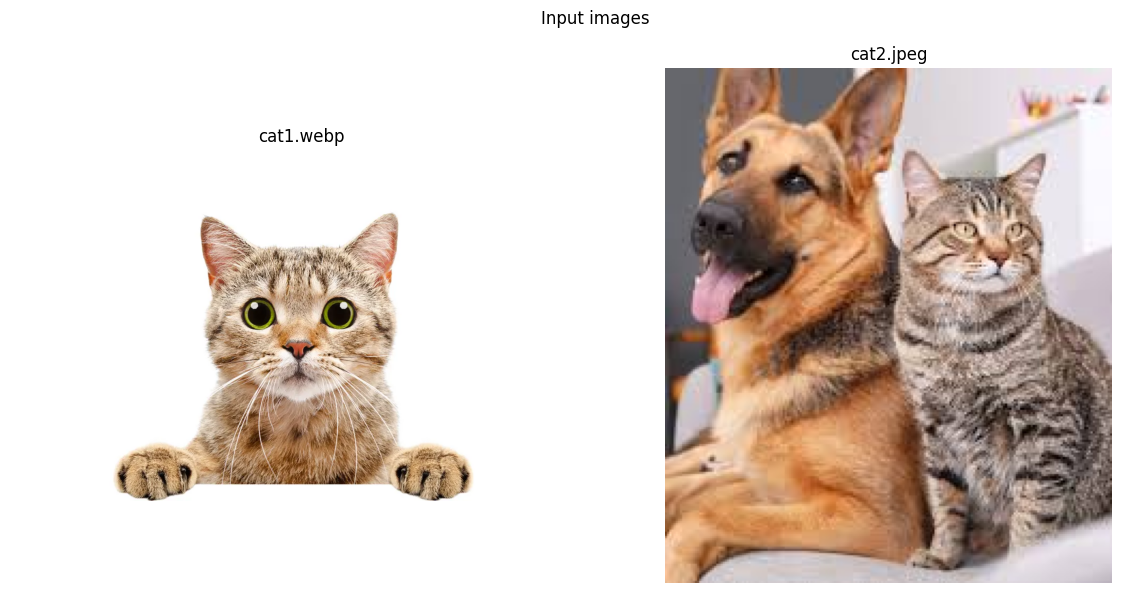

In [2]:
def imread_any(path: Path) -> np.ndarray:
    """Read an image as BGR uint8 using OpenCV; fall back to PIL if needed."""
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is not None:
        return img
    # Fallback (sometimes useful for unusual codecs)
    try:
        from PIL import Image  # type: ignore
    except Exception as e:
        raise RuntimeError(f"cv2.imread failed for {path.name} and Pillow is not available.") from e
    with Image.open(path) as pil:
        rgb = np.array(pil.convert("RGB"), dtype=np.uint8)
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

def show_images_grid(items, cols=2, figsize=(10, 6), title=None):
    """items: list of (name, rgb_image)"""
    rows = int(np.ceil(len(items) / cols))
    plt.figure(figsize=figsize)
    if title:
        plt.suptitle(title)
    for i, (name, rgb) in enumerate(items, start=1):
        ax = plt.subplot(rows, cols, i)
        ax.imshow(rgb)
        ax.set_title(name)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

loaded = []
for p in image_paths:
    bgr = imread_any(p)
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    loaded.append((p.name, bgr, rgb))

show_images_grid([(name, rgb) for name, _, rgb in loaded], cols=2, figsize=(12, 6), title="Input images")

## Step 2–3: Load Haar cascade and run detection

We load the pre-trained Haar cascade and call `detectMultiScale` with the required parameters:
- `scaleFactor = 1.1`
- `minNeighbors = 5`
- `minSize = (50, 50)`

We then draw rectangles around detected cat faces and write the label **"Cat"** near each detection.

Optional preprocessing: applying a small **Gaussian blur** can sometimes reduce noise and stabilize detections (but it can also reduce details).

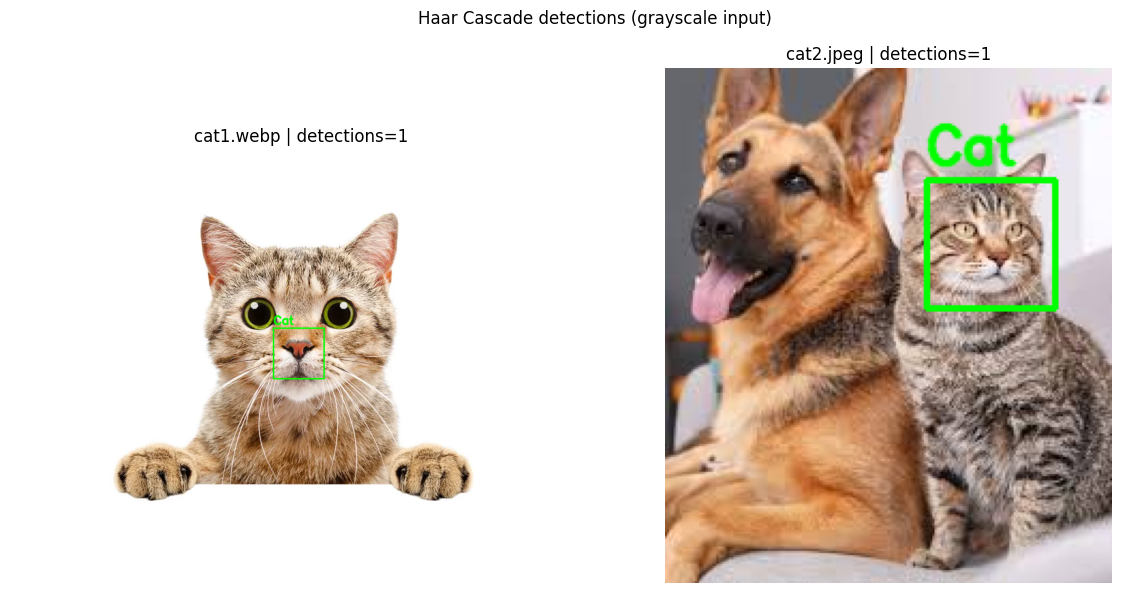

In [3]:
cascade_file = os.path.join(MODELS_DIR, "haarcascade_frontalcatface_extended.xml")
cat_cascade = cv2.CascadeClassifier(cascade_file)
if cat_cascade.empty():
    raise RuntimeError(f"Failed to load cascade from: {cascade_file}")

SCALE_FACTOR = 1.1
MIN_NEIGHBORS = 5
MIN_SIZE = (50, 50)

def to_detection_channel(bgr: np.ndarray, mode: str) -> np.ndarray:
    """Return an 8-bit single-channel image for Haar detection."""
    if mode == "gray":
        return cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    if mode == "v_channel":
        hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
        return hsv[:, :, 2]  # Value
    if mode == "b_channel":
        return bgr[:, :, 0]
    if mode == "g_channel":
        return bgr[:, :, 1]
    if mode == "r_channel":
        return bgr[:, :, 2]
    raise ValueError(f"Unknown mode: {mode}")

def detect_cats(
    bgr: np.ndarray,
    *,
    channel_mode: str = "gray",
    blur: bool = False,
    blur_ksize: int = 5,
    scaleFactor: float = SCALE_FACTOR,
    minNeighbors: int = MIN_NEIGHBORS,
    minSize: tuple[int, int] = MIN_SIZE,
    ) -> np.ndarray:
    """Run Haar cascade cat-face detection. Returns Nx4 array of (x,y,w,h)."""
    chan = to_detection_channel(bgr, channel_mode)
    if blur:
        k = max(3, blur_ksize)
        if k % 2 == 0:
            k += 1
        chan = cv2.GaussianBlur(chan, (k, k), 0)
    rects = cat_cascade.detectMultiScale(
        chan,
        scaleFactor=scaleFactor,
        minNeighbors=minNeighbors,
        minSize=minSize,
    )
    return np.array(rects) if len(rects) else np.zeros((0, 4), dtype=int)

def draw_detections(bgr: np.ndarray, rects: np.ndarray, label: str = "Cat") -> np.ndarray:
    out = bgr.copy()
    for (x, y, w, h) in rects:
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
        # Place text slightly above the rectangle when possible
        tx, ty = x, max(20, y - 8)
        cv2.putText(
            out, label, (tx, ty),
            cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2, cv2.LINE_AA
        )
    return out

# Run detection (correct/default pipeline: grayscale) and visualize
results = []
for name, bgr, _ in loaded:
    rects = detect_cats(bgr, channel_mode="gray", blur=False)
    annotated_bgr = draw_detections(bgr, rects, label="Cat")
    annotated_rgb = cv2.cvtColor(annotated_bgr, cv2.COLOR_BGR2RGB)
    results.append((f"{name} | detections={len(rects)}", annotated_rgb))

show_images_grid(results, cols=2, figsize=(12, 6), title="Haar Cascade detections (grayscale input)")

## Step 4: Grayscale vs "Color" input (analysis)

**Important detail about OpenCV Haar cascades:** `detectMultiScale` expects a **single-channel (grayscale) image**.
So you *cannot* directly feed a 3-channel BGR/RGB image into the detector in a meaningful way.

To still analyze the effect of different input representations, we will compare:
- **Grayscale (recommended)**: `cv2.cvtColor(..., COLOR_BGR2GRAY)`
- **HSV Value channel** (derived from color): captures brightness information differently than standard grayscale
- **Single B/G/R channel** (derived from color): shows how choosing one color channel can change detections

We will keep the detection parameters identical and only change the input channel preprocessing.

Unexpected: detectMultiScale accepted a 3-channel image.


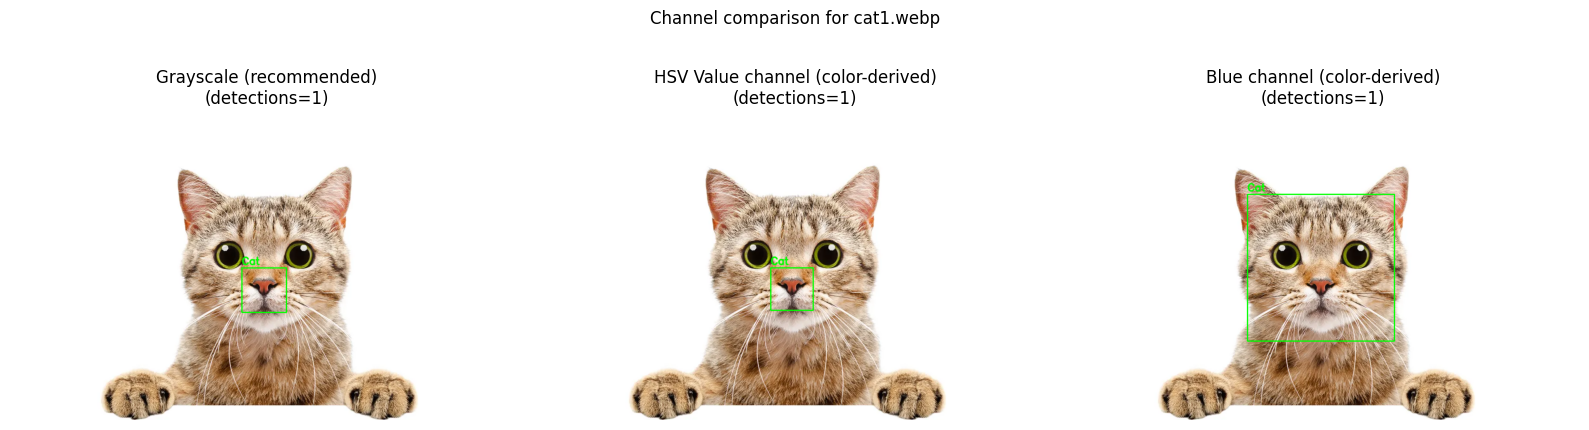

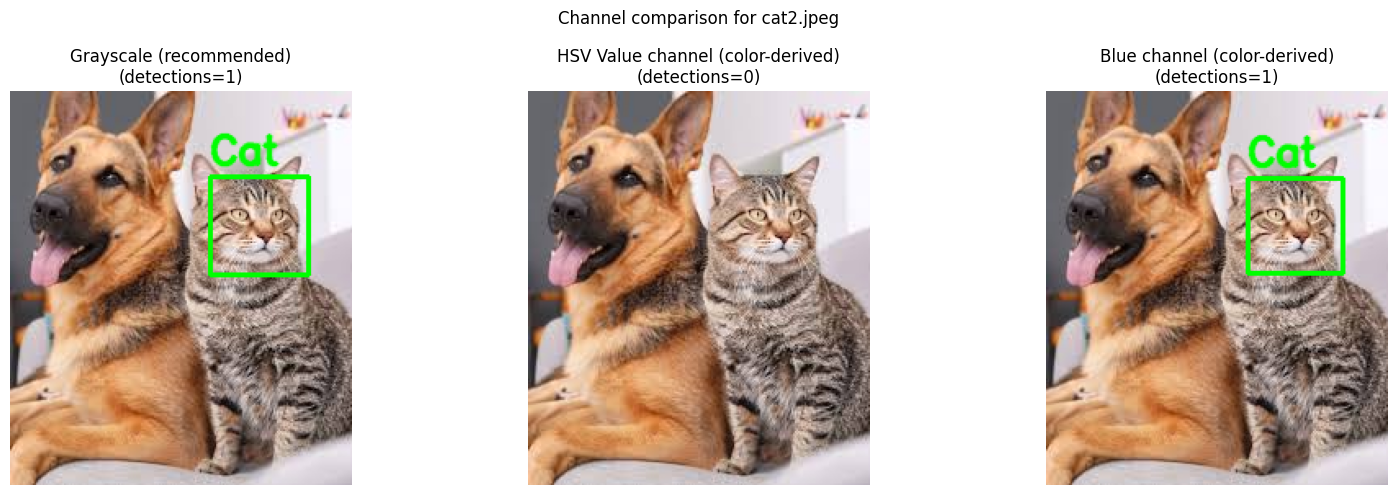

In [4]:
# Compare different input channel representations
modes = ["gray", "v_channel", "b_channel"]  # keep it short & focused
mode_titles = {
    "gray": "Grayscale (recommended)",
    "v_channel": "HSV Value channel (color-derived)",
    "b_channel": "Blue channel (color-derived)",
}

# Show what happens if someone tries to pass a 3-channel image directly
try:
    _ = cat_cascade.detectMultiScale(loaded[0][1])  # BGR image (3 channels)
    print("Unexpected: detectMultiScale accepted a 3-channel image.")
except Exception as e:
    print("As expected, 3-channel input is not valid for Haar cascades:")
    print(" ", repr(e))

for name, bgr, _ in loaded:
    items = []
    for mode in modes:
        rects = detect_cats(bgr, channel_mode=mode, blur=False)
        annotated = draw_detections(bgr, rects, label="Cat")
        rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)
        items.append((f"{mode_titles[mode]}\n(detections={len(rects)})", rgb))
    show_images_grid(items, cols=len(modes), figsize=(16, 5), title=f"Channel comparison for {name}")

## Step 5: Rotation robustness test (90°)

Haar cascades are usually trained on **upright** objects. They are not inherently rotation-invariant.
So after rotating the image by **90 degrees**, we typically expect:
- fewer detections, or
- missed detections, or
- occasional false positives in textured regions.

We will rotate each image and run the *same detector + same parameters* to see how performance changes.

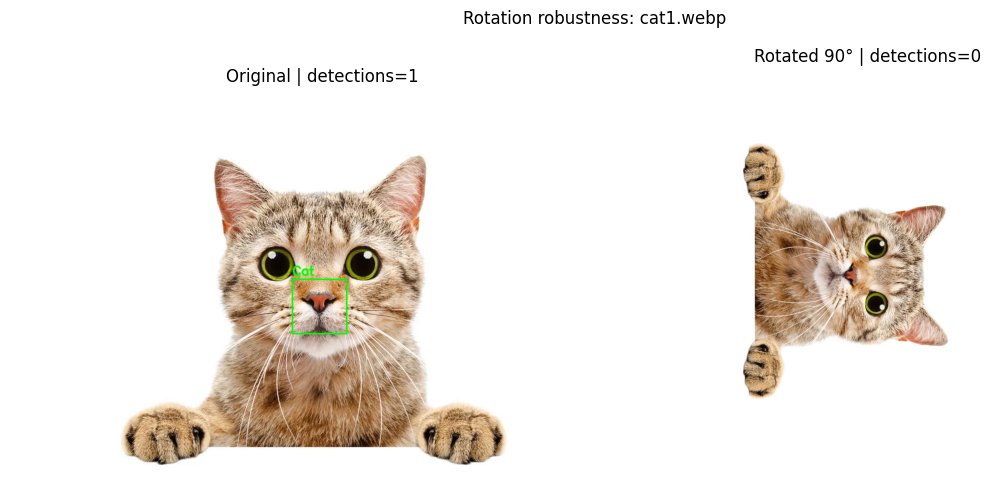

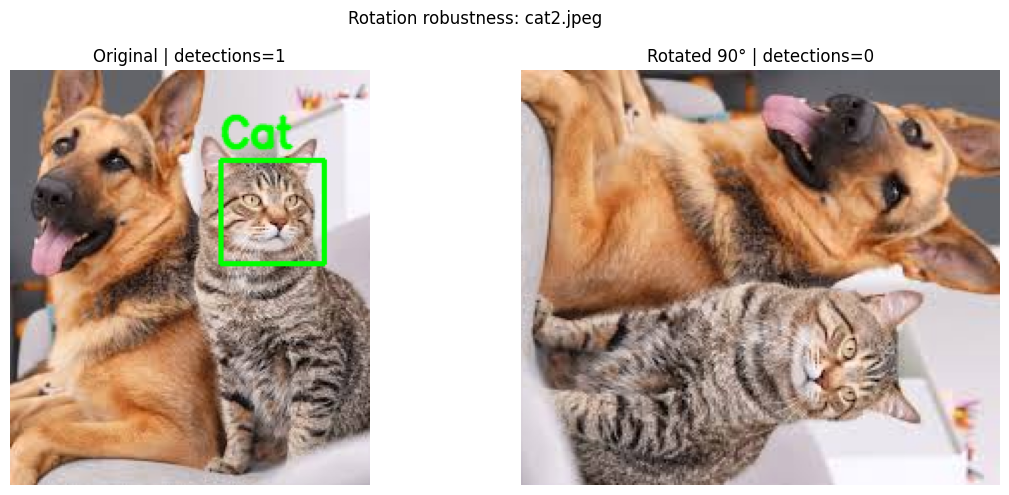

In [5]:
# Rotate images by 90 degrees and run detection
for name, bgr, _ in loaded:
    rotated = cv2.rotate(bgr, cv2.ROTATE_90_CLOCKWISE)

    rects_orig = detect_cats(bgr, channel_mode="gray", blur=False)
    rects_rot = detect_cats(rotated, channel_mode="gray", blur=False)

    vis_orig = cv2.cvtColor(draw_detections(bgr, rects_orig), cv2.COLOR_BGR2RGB)
    vis_rot = cv2.cvtColor(draw_detections(rotated, rects_rot), cv2.COLOR_BGR2RGB)

    show_images_grid(
        [(f"Original | detections={len(rects_orig)}", vis_orig),
         (f"Rotated 90° | detections={len(rects_rot)}", vis_rot)],
        cols=2,
        figsize=(12, 5),
        title=f"Rotation robustness: {name}",
    )

## conclusions

- **Grayscale is the correct input** for Haar cascades; OpenCV generally rejects 3-channel input.
- Different *color-derived single-channel* choices (like HSV Value or a single B/G/R channel) can change contrast patterns and may slightly change detections — but results are often less stable than standard grayscale.
- **Rotation by 90°** usually reduces detections because the cascade was trained on upright cat faces.